In [1]:
import xarray as xr

time = ("2011-12", "2011-12")

observation_data = (
    xr.open_dataset("inputs/Processed_Johan_Buoys.nc")
    .sel(time=slice(time[0], time[1]))
    .resample(time="1H")
    .mean()
)
# metamodel_data = (
#     xr.open_dataset("outputs/Metamodel_Reconstruction_in_Points_2000_2018.nc")
#     .sel(time=slice(time[0], time[1]))
#     .isel(stations=slice(-9, None))
# )
metamodel_data = xr.concat(
    [
        xr.open_dataset("outputs/1500_reconstructed_month_first_tp.nc"),
        xr.open_dataset("outputs/1500_reconstructed_month_second_tp.nc"),
    ],
    dim="time",
).isel(stations=slice(-9, None))
dynamic_data = xr.open_dataset("outputs/Dynamic_Cases_201106_201112.nc").sel(
    time=slice(time[0], time[1])
)
era5_data = xr.open_dataset("inputs/ERA5_forcing_goals_2000_2025.nc").sel(
    time=slice(time[0], time[1])
)
codec_data = xr.open_dataset("inputs/CODEC_in_ERA5_coords.nc").sel(
    time=slice(time[0], time[1])
)

/home/tausiaj/miniforge3/envs/bluemath-311-dev/lib/python3.11/site-packages/xarray/groupers.py:530: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  self.index_grouper = pd.Grouper(


In [2]:
metamodel_data

<xarray.Dataset> Size: 327kB
Dimensions:     (time: 744, stations: 9)
Coordinates:
  * time        (time) datetime64[ns] 6kB 2011-12-01 ... 2011-12-31T23:00:00
Dimensions without coordinates: stations
Data variables:
    bulk_hm0    (time, stations) float64 54kB 1.335 1.332 ... 0.7373 0.9243
    sea_hm0     (time, stations) float64 54kB 0.8176 0.8131 ... 0.4106 0.7455
    swell1_hm0  (time, stations) float64 54kB 0.392 0.3901 ... 0.1647 0.3557
    swell2_hm0  (time, stations) float64 54kB 0.3833 0.3832 ... 0.3421 0.3568
    swell3_hm0  (time, stations) float64 54kB 0.2254 0.2252 ... 0.03936 0.02267
    sum_hm0     (time, stations) float64 54kB 1.01 1.005 1.504 ... 0.5606 0.9

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19
Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19
Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19
Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of 

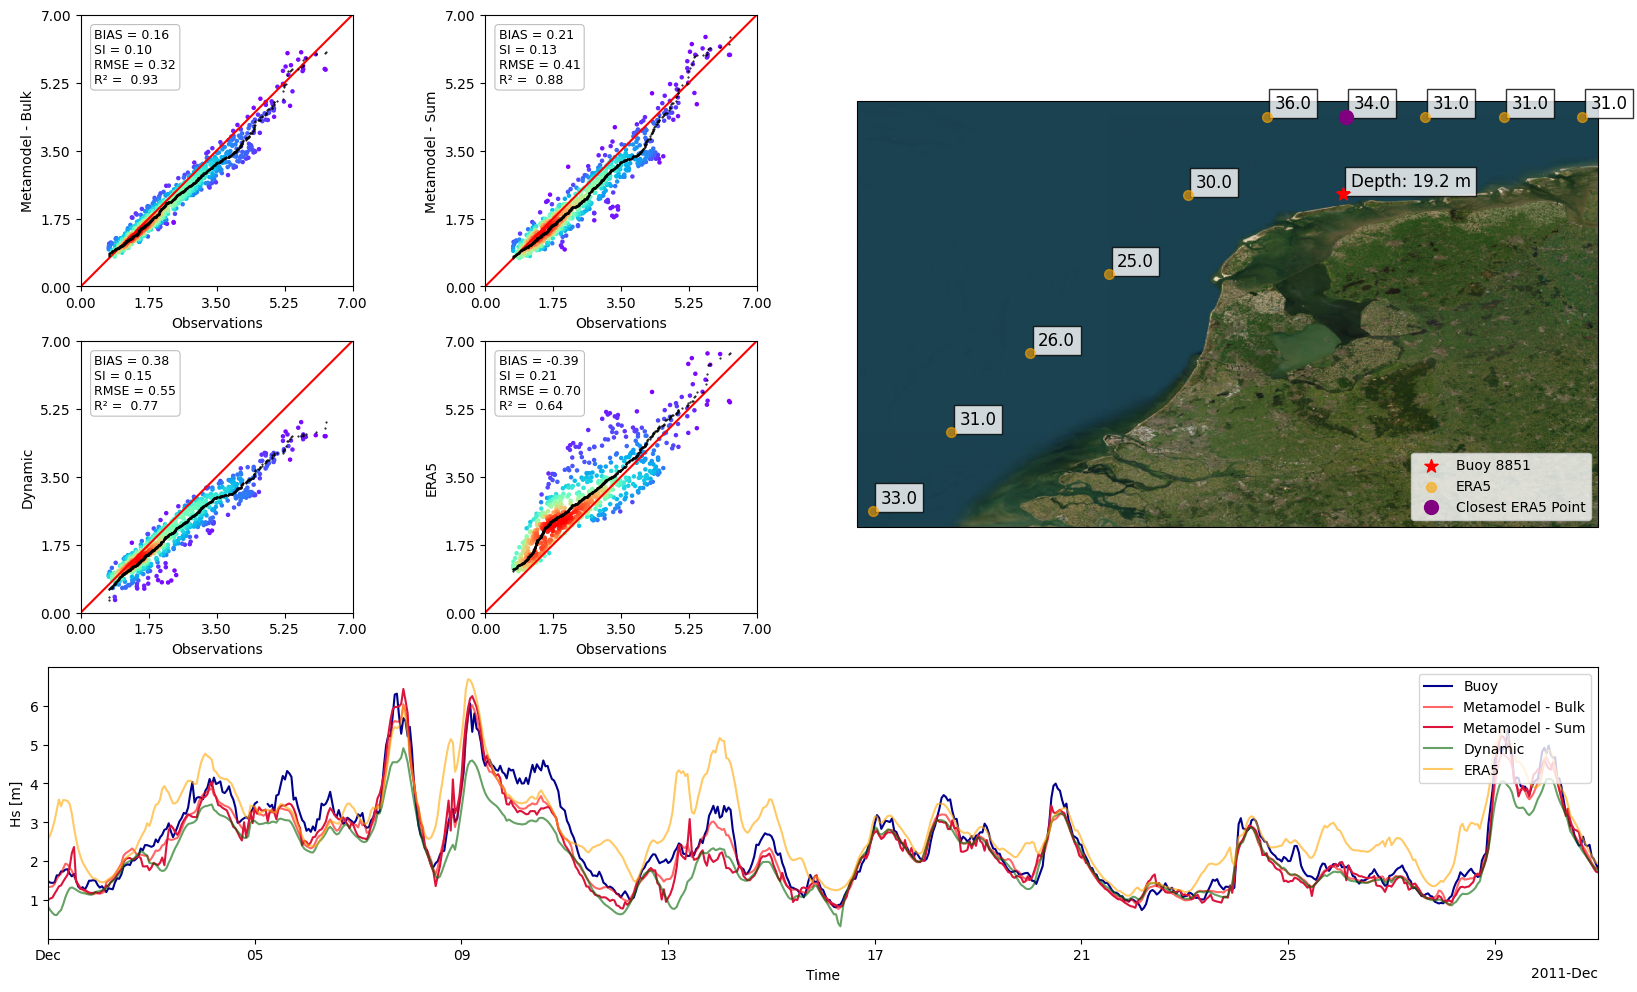

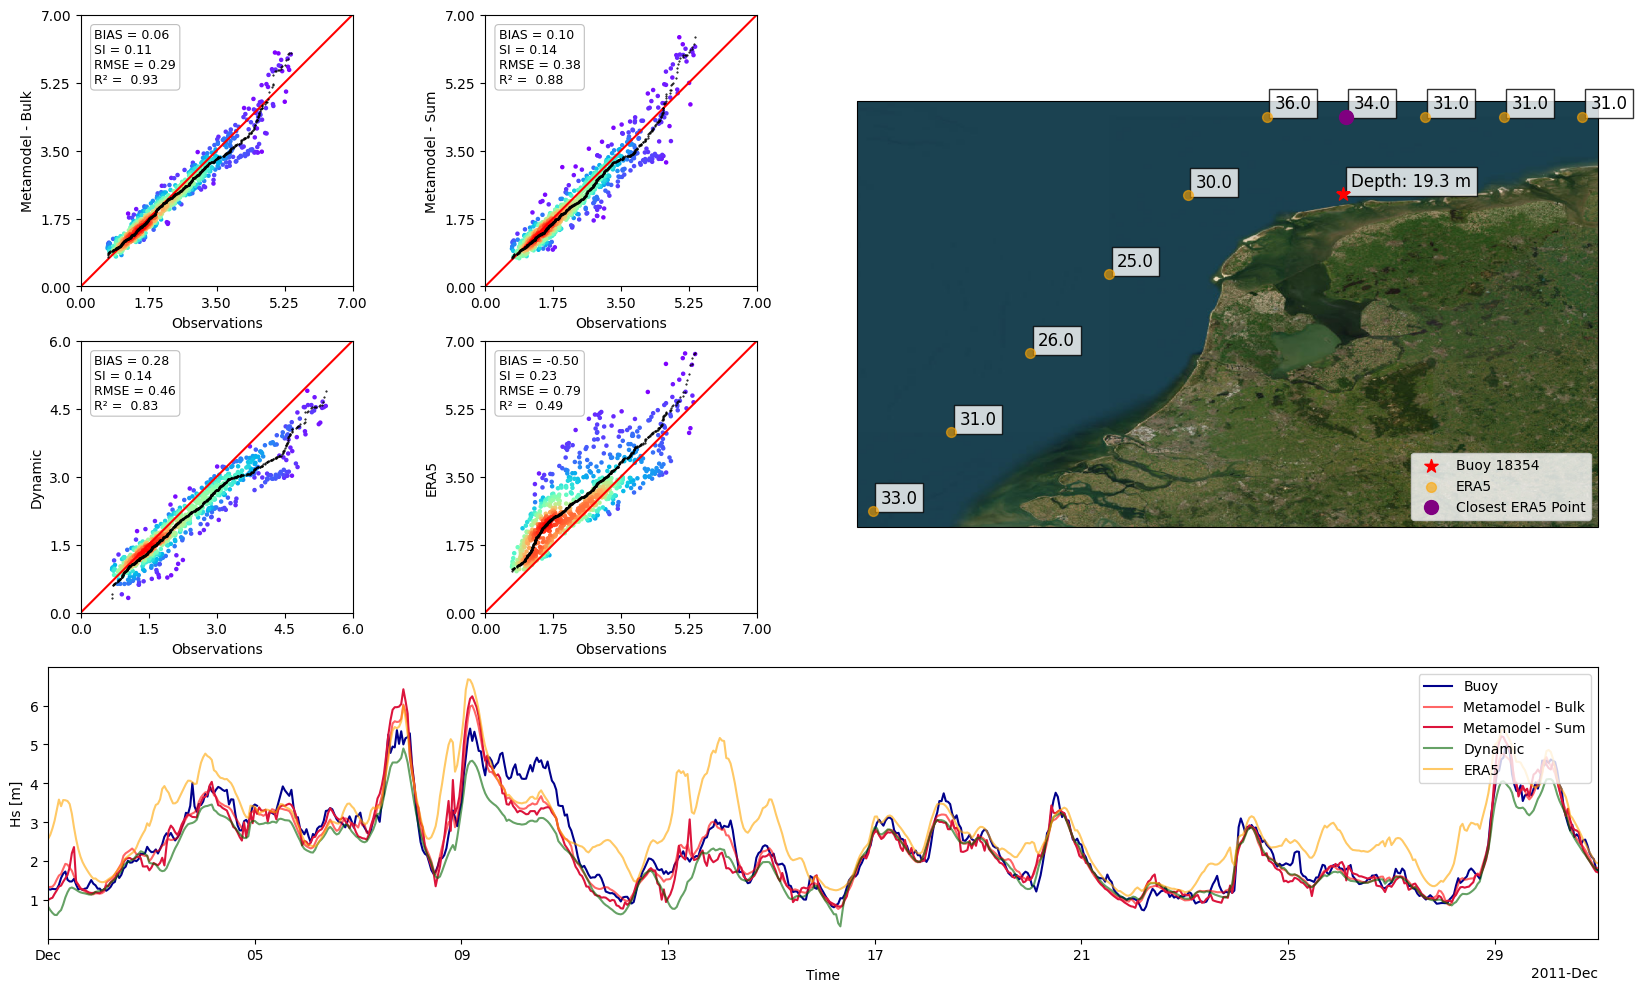

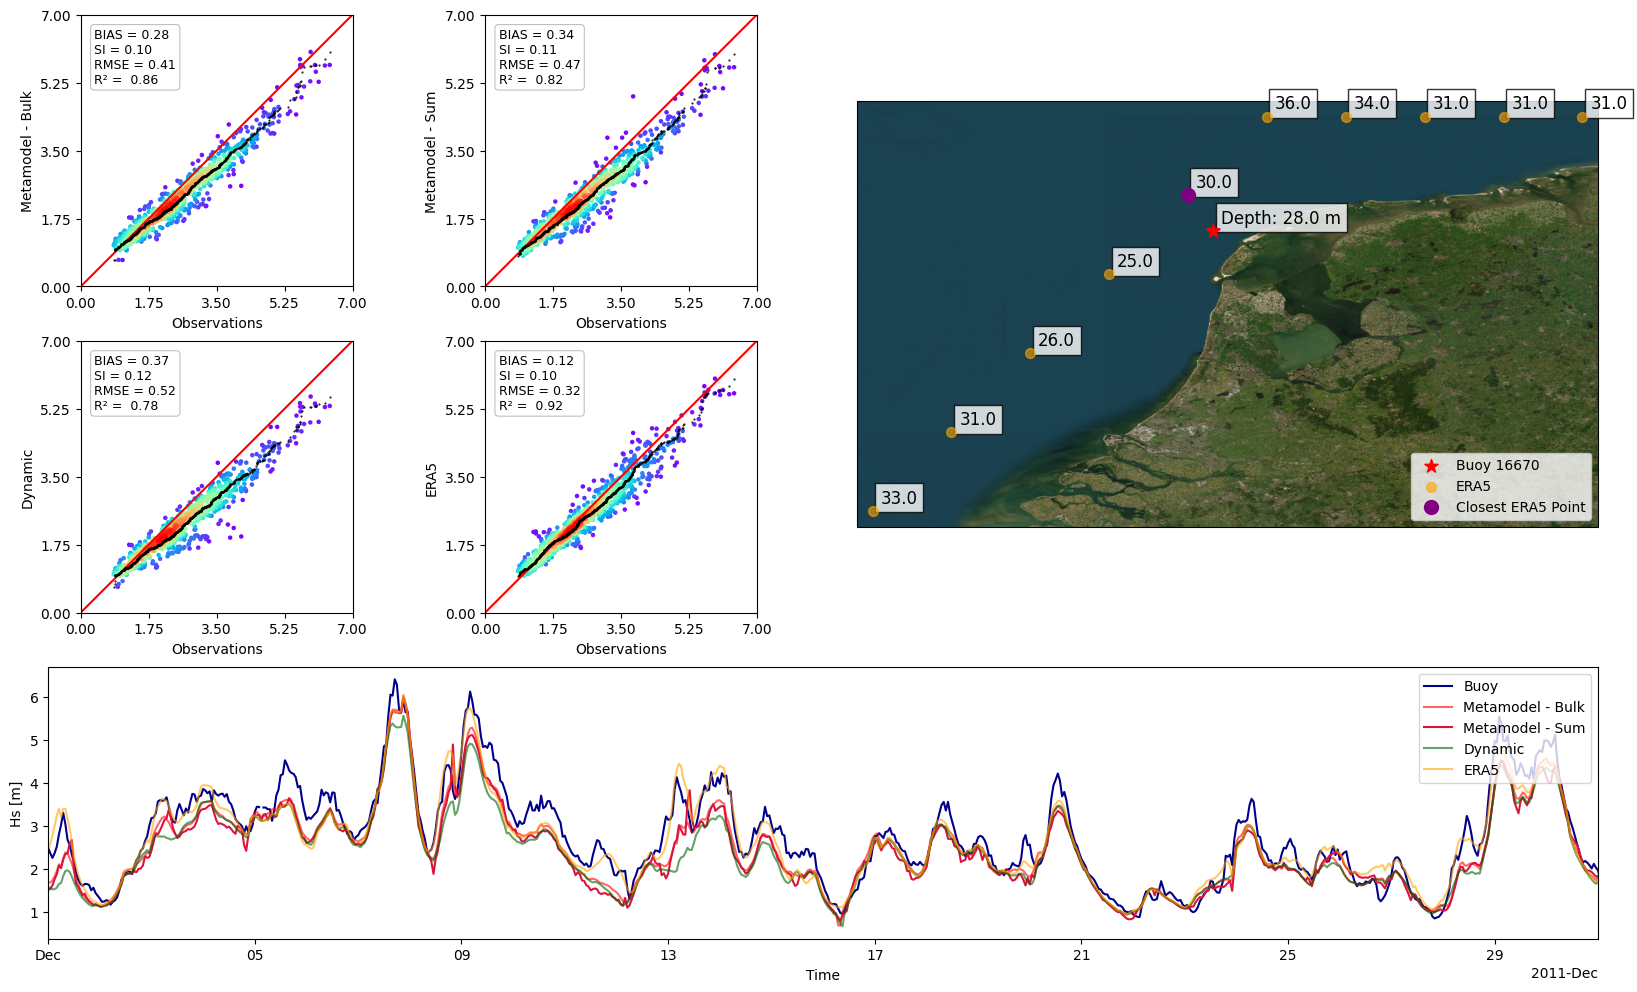

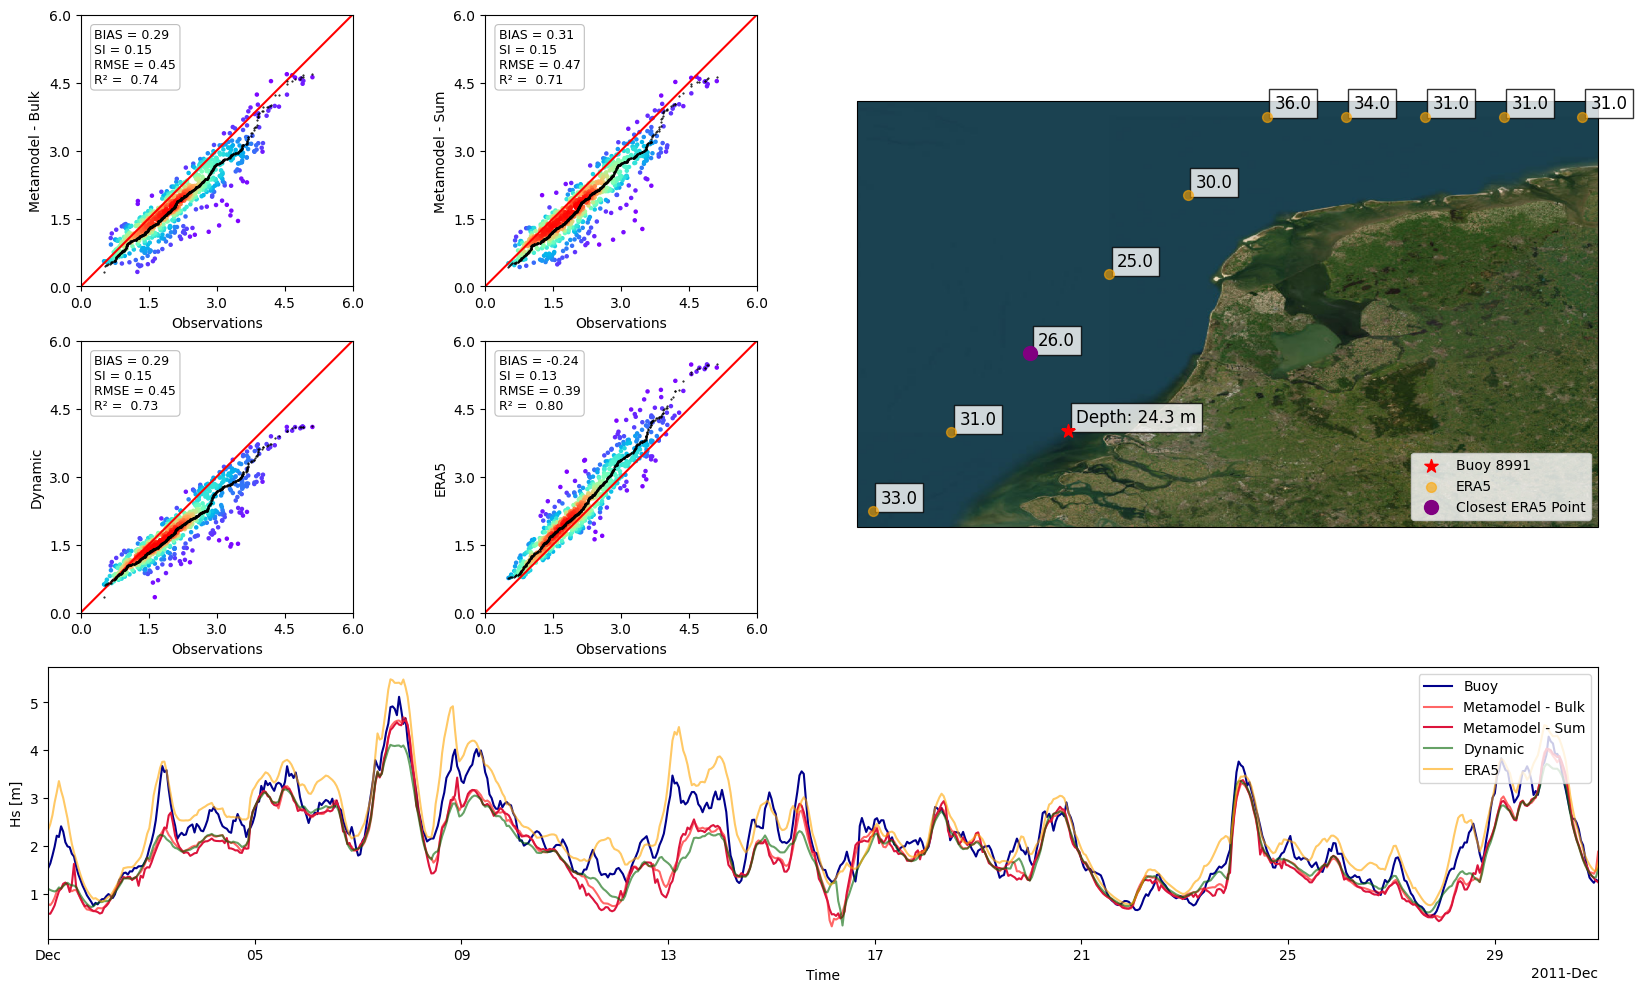

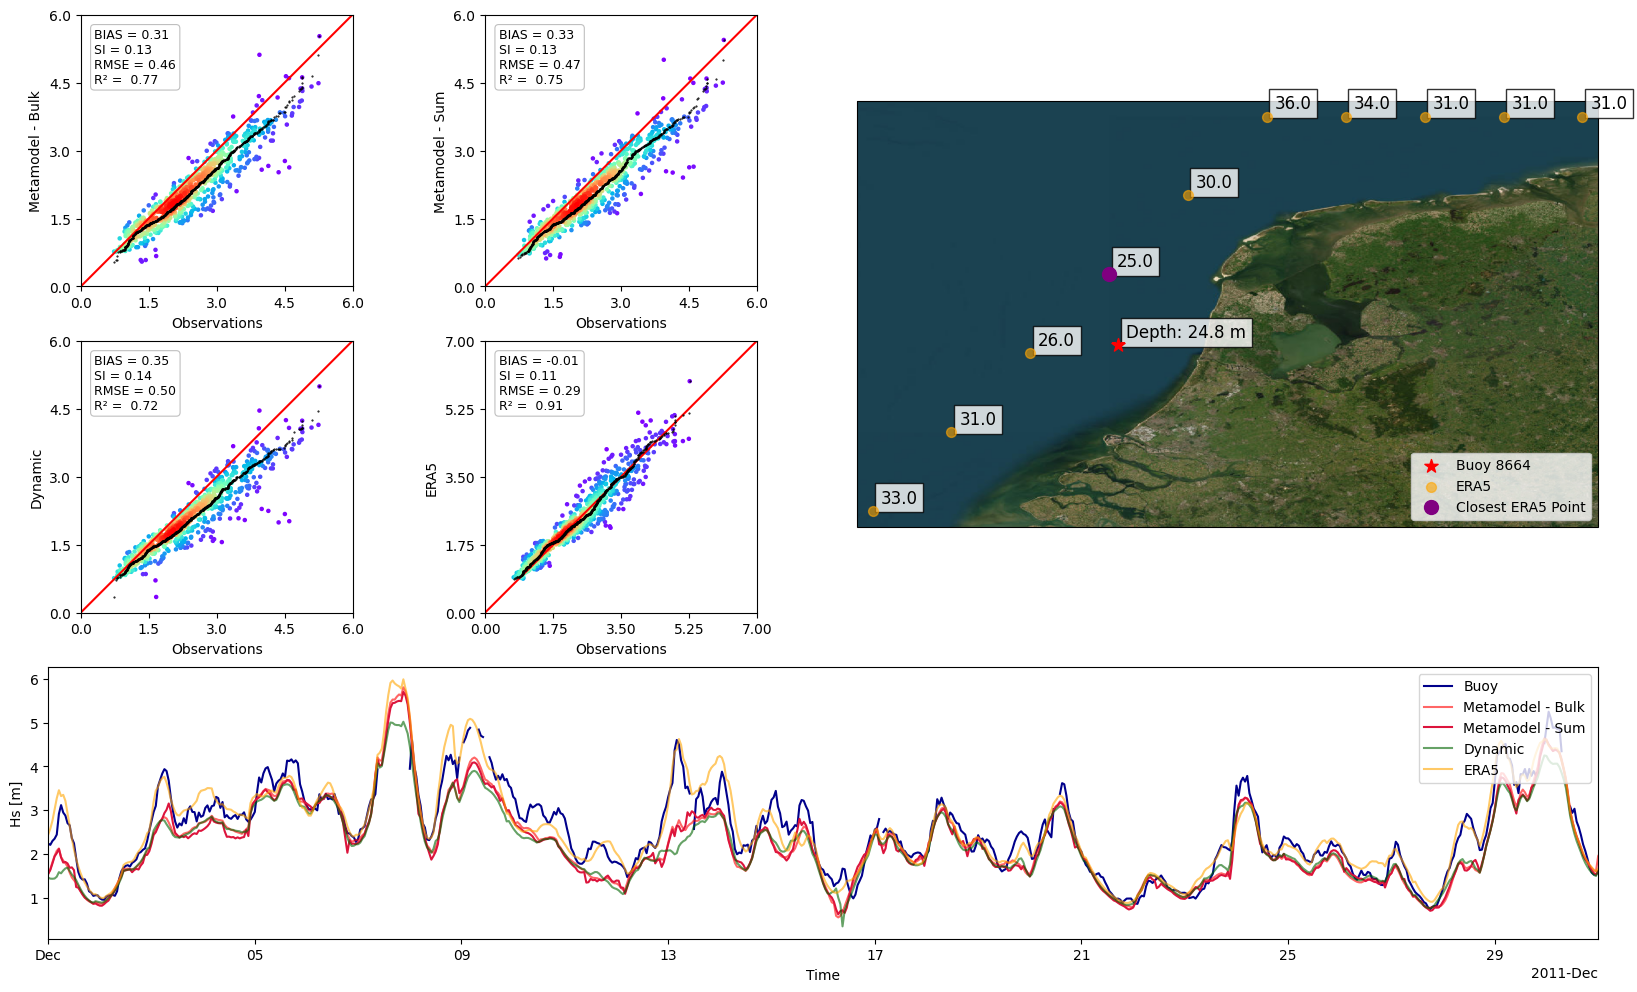

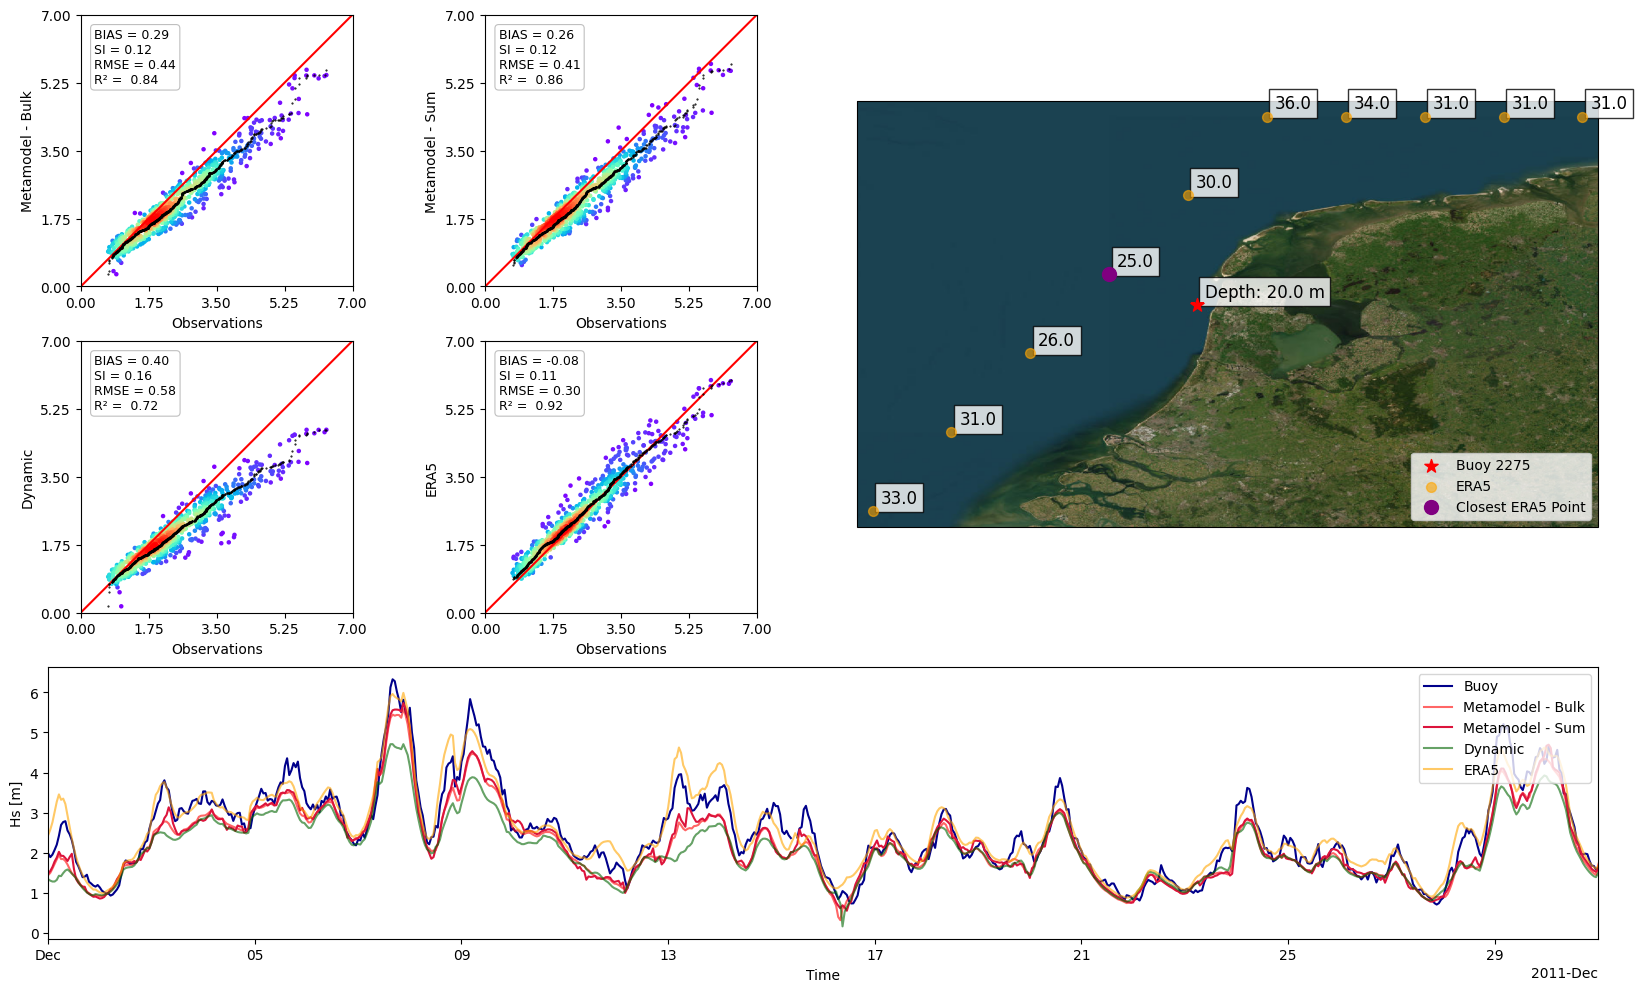

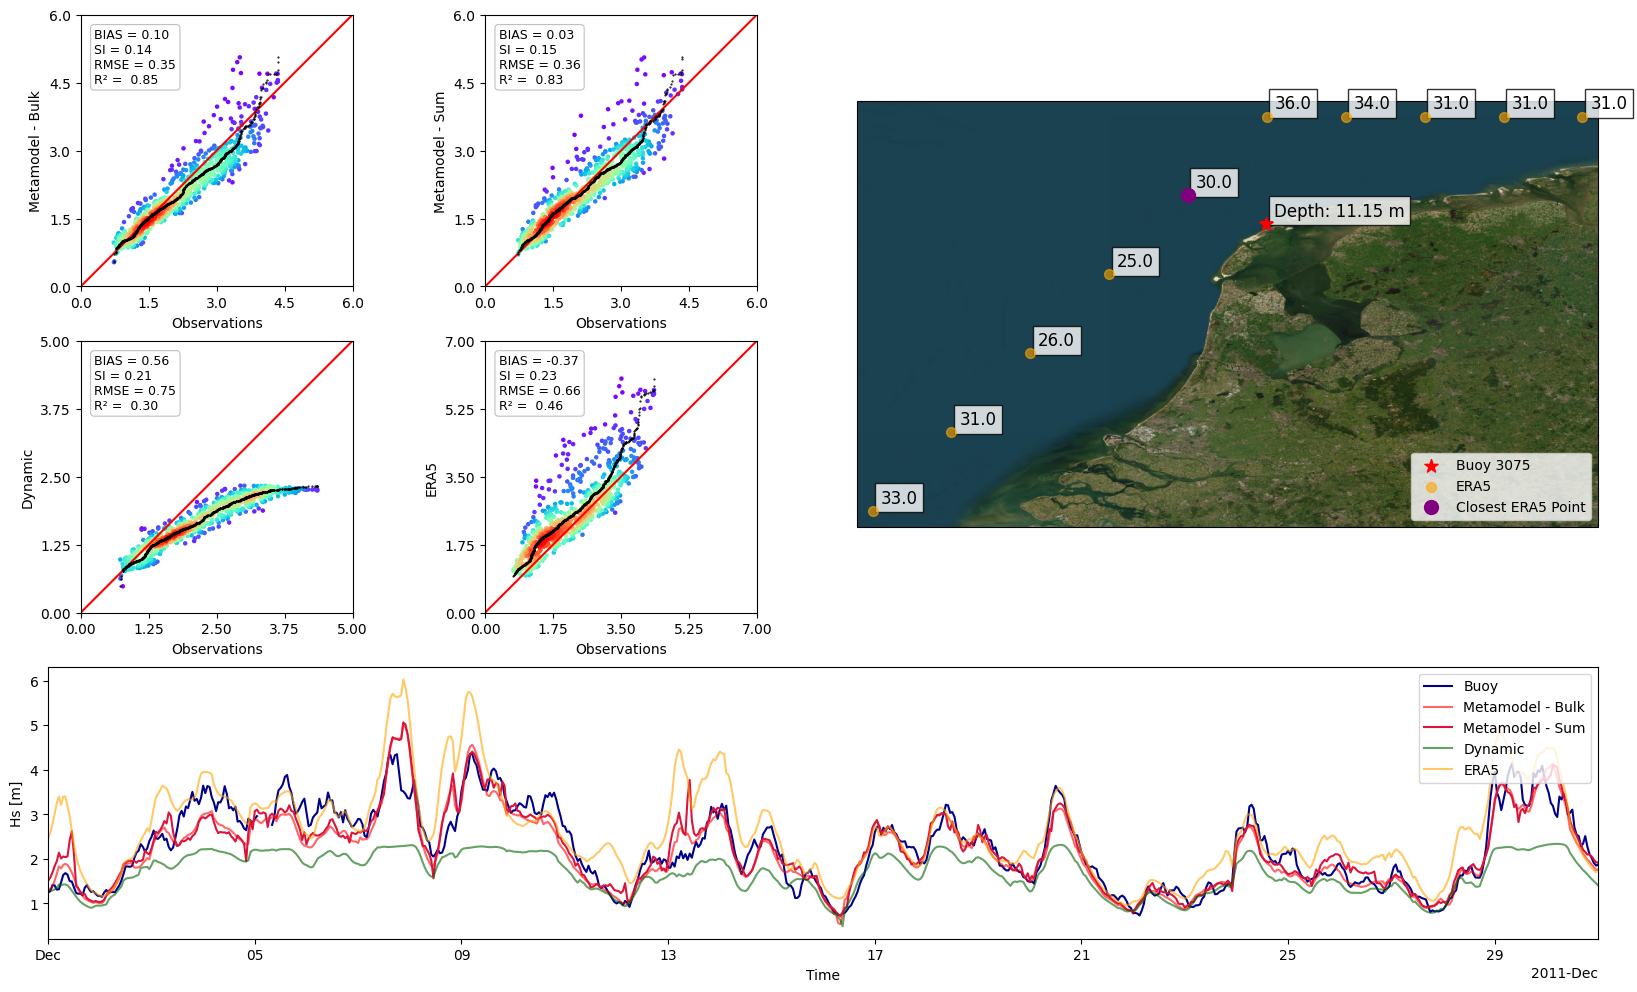

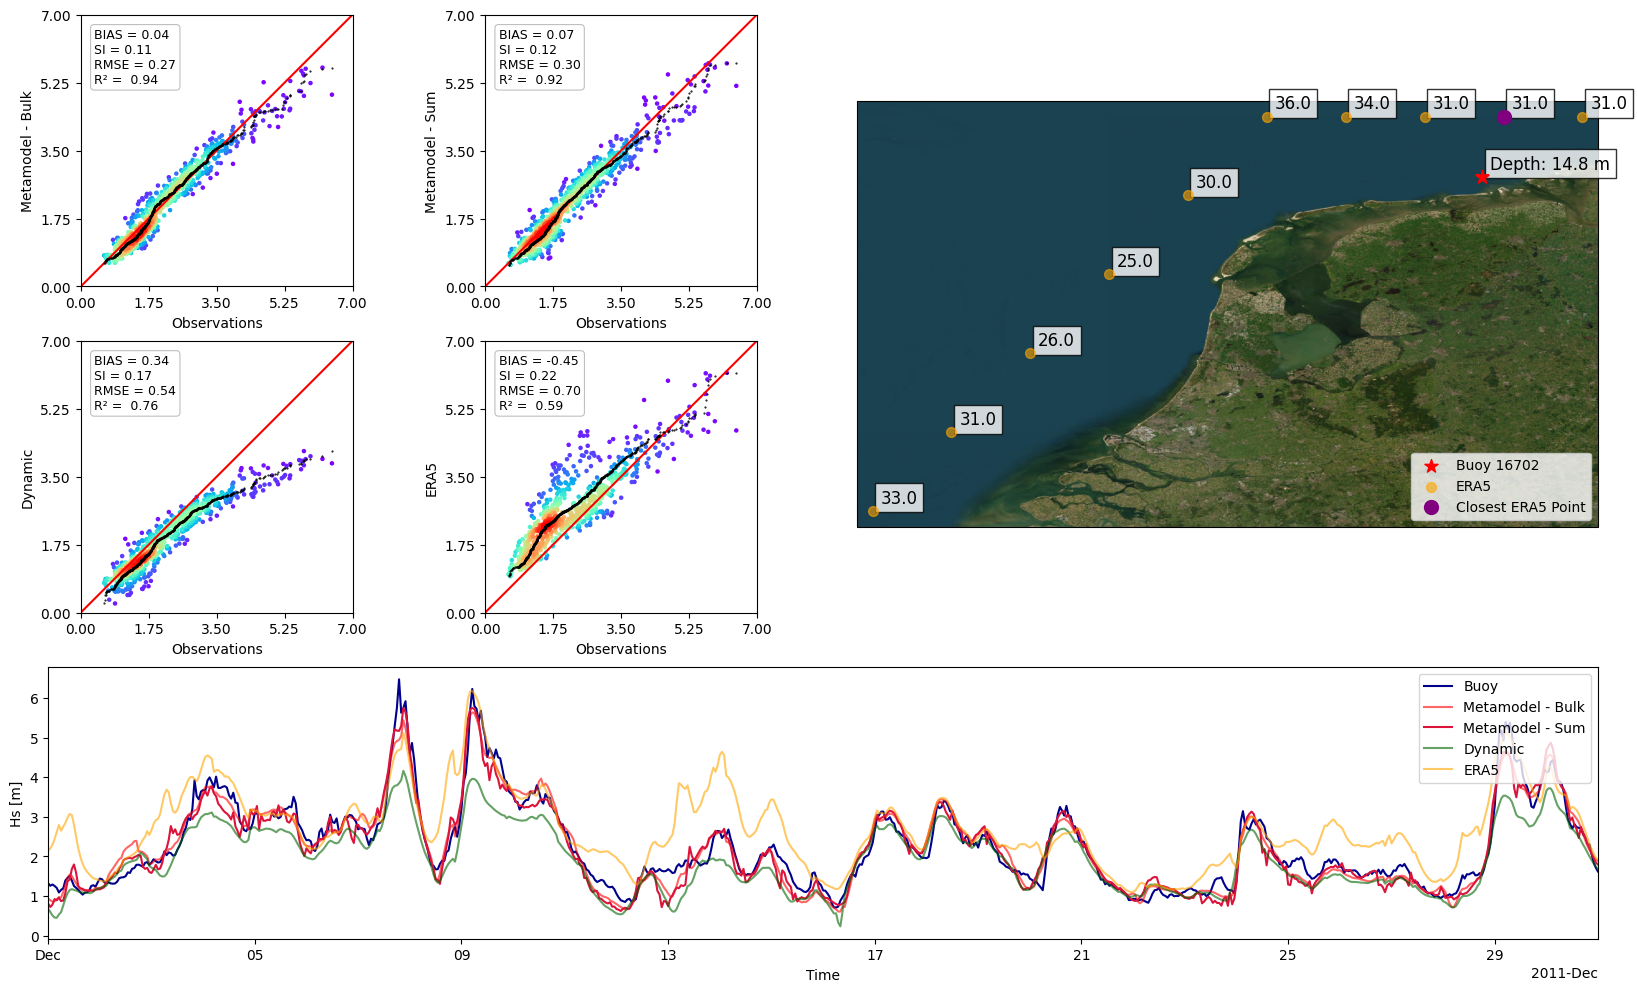

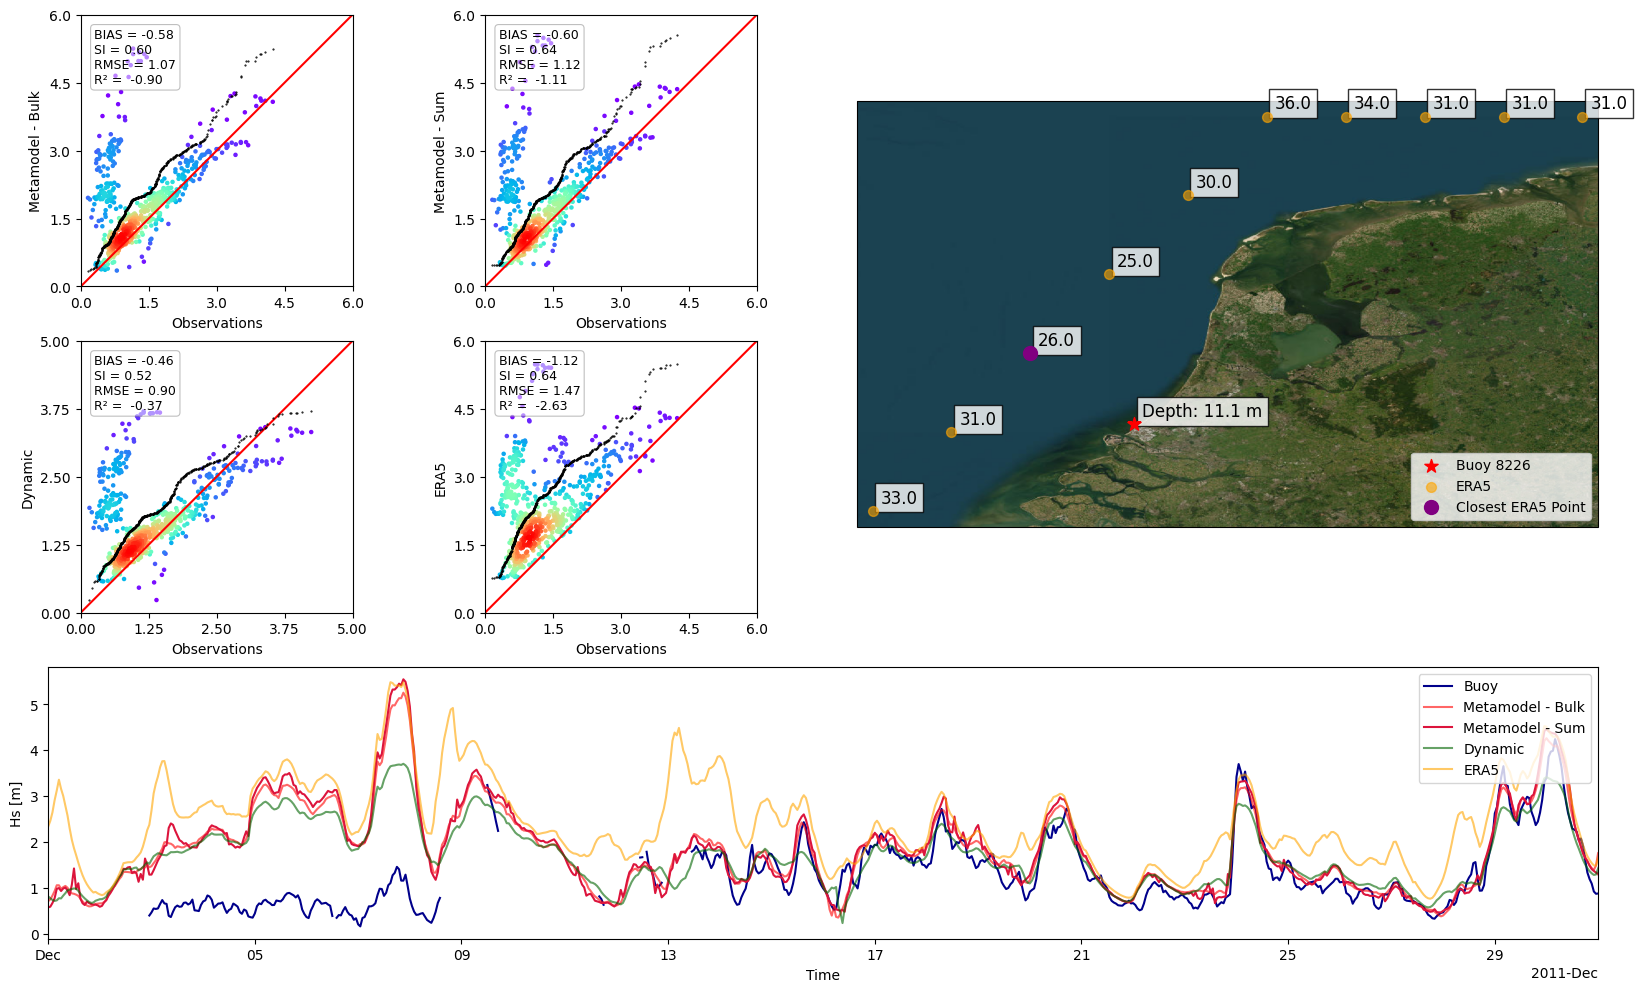

In [3]:
from utils.validation import plot_all_buoy_validation_figures

plot_all_buoy_validation_figures(
    observation_data=observation_data,
    metamodel_data=metamodel_data,
    dynamic_data=dynamic_data,
    era5_data=era5_data,
    figsize=(20, 12),
);